In [81]:
#import the library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [82]:
#load the datasets
df = pd.read_csv("../../LogisticRegression/social_network_ads.csv")
df.head()

,User_ID,Age,EstimatedSalary,Purchased
0,10001,19,19000,0
1,10002,35,42000,0
2,10003,26,34000,0
3,10004,27,72000,1
4,10005,19,24000,0


In [83]:
#Drop the User_ID
df.drop(columns="User_ID",inplace=True)

In [84]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,42000,0
2,26,34000,0
3,27,72000,1
4,19,24000,0


In [85]:
# Differentating the feature and labels data.
x = df.iloc[:,:-1]
y = df['Purchased']

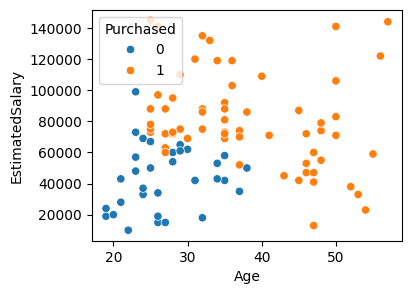

In [86]:
plt.figure(figsize=(4,3))
sns.scatterplot(x = 'Age' , y = 'EstimatedSalary' , hue='Purchased',data=df)
plt.show()

In [87]:
#  splitting the data into train test split.
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [88]:
# saling the data using standard scalar.
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train_scaled = sc.fit_transform(x_train)
x_test_scaled = sc.transform(x_test)

In [89]:
x_train_scaled = pd.DataFrame(sc.fit_transform(x_train),columns=x_train.columns,index=x_train.index)
x_test_scaled = pd.DataFrame(sc.transform(x_test),columns=x_test.columns,index=x_test.index)

In [90]:
# Display the scaled training features
x_train_scaled.head()

,Age,EstimatedSalary
55,-0.894698,0.139347
88,0.130744,0.139347
26,2.079084,-1.404661
42,1.976540,-1.095860
69,-1.099787,0.942231


In [91]:
# Train the model.
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(criterion='entropy',max_depth=7)
model.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [92]:
# model accuracy test
model.score(x_test,y_test) * 100 , model.score(x_train,y_train) * 100

(95.0, 97.5)

In [102]:
y_pred = model.predict(x_test)
print(y_pred)

[1 1 0 1 1 1 1 1 1 0 1 0 0 1 1 0 0 1 0 1]


In [103]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.95

In [93]:
model.predict([[19,19000]])

array([0])

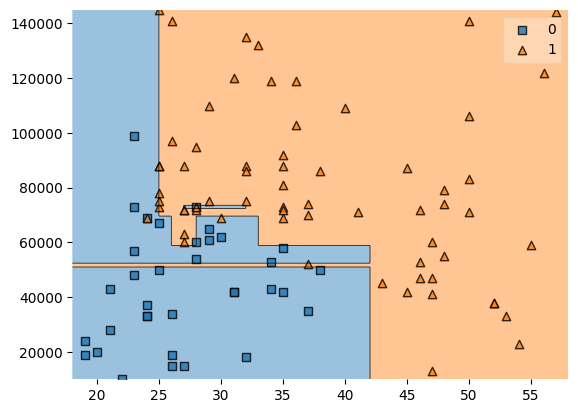

In [94]:
# Data visualize the datasets.
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x.to_numpy() , y.to_numpy() , clf=model)
plt.show()

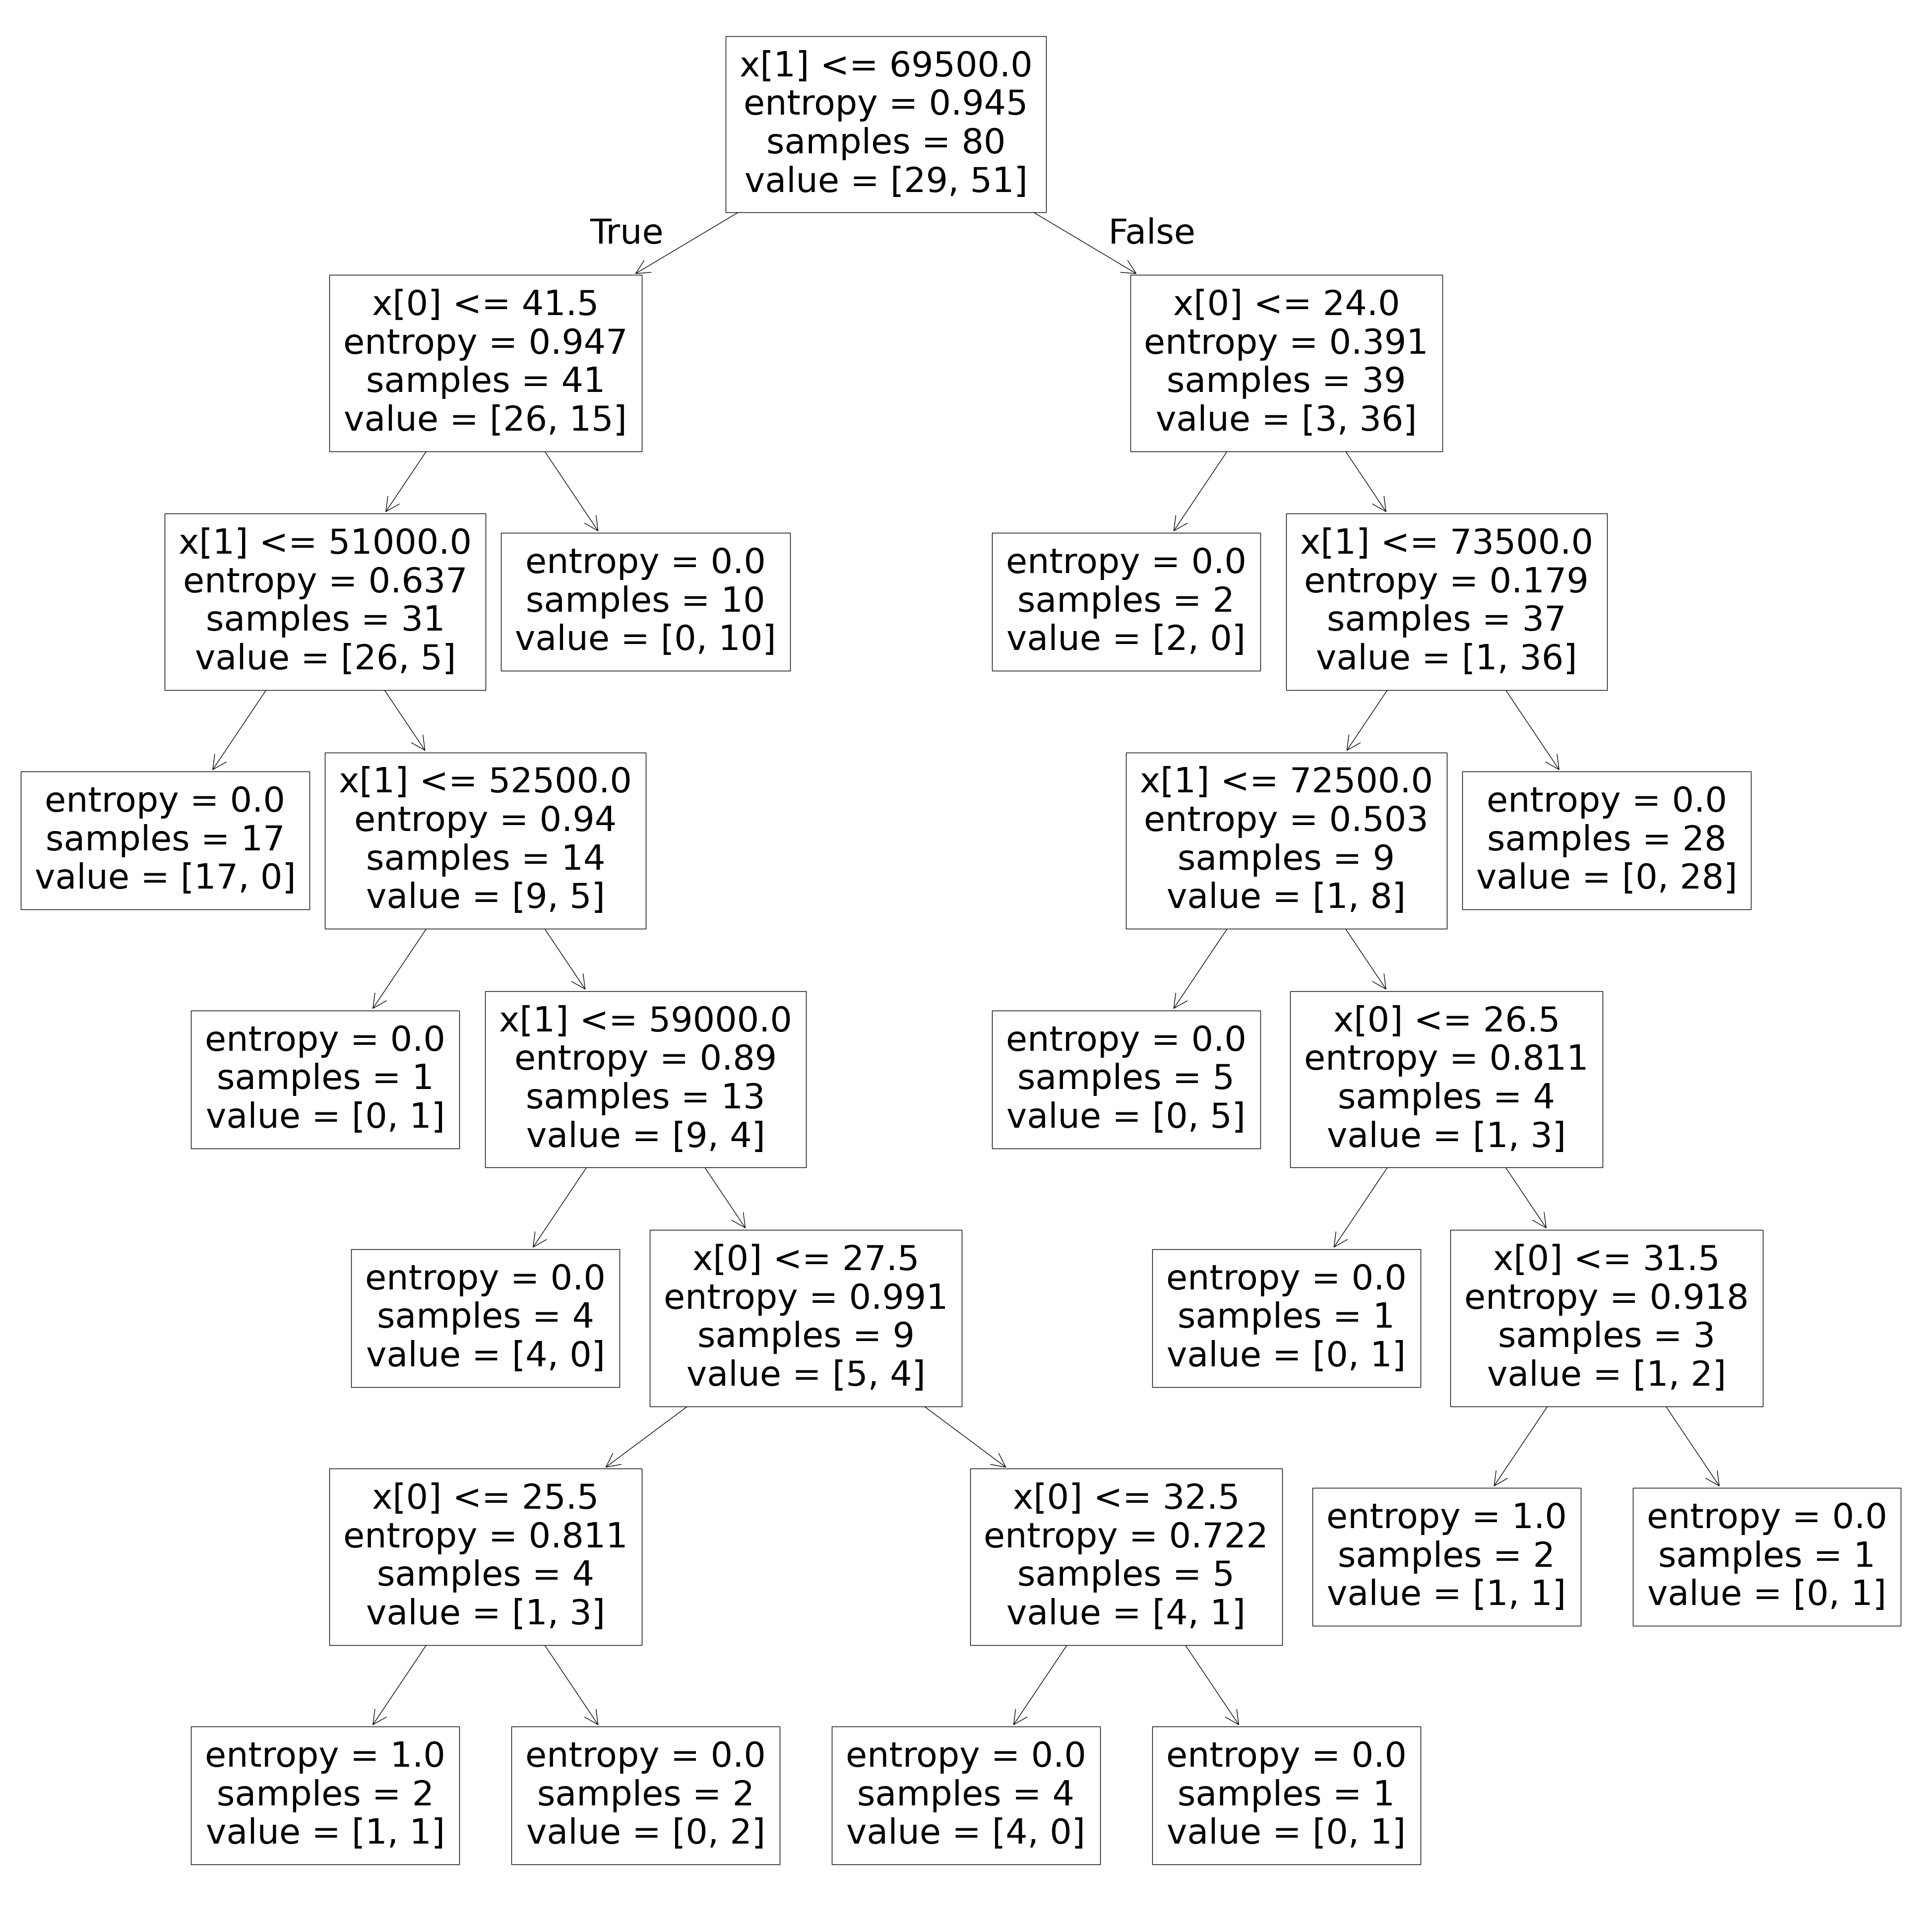

<Figure size 640x480 with 0 Axes>

In [104]:
# tree visualize
from sklearn.tree import plot_tree
plt.figure(figsize=(50,50))
plot_tree(model)
plt.show()
plt.savefig("tree.jpg")

In [96]:
from scipy.stats import entropy
counts = df['Age'].value_counts()
result = entropy(counts, base=2)
print(result)

4.775175975368541


In [97]:
from scipy.stats import entropy
counts = df['EstimatedSalary'].value_counts()
result = entropy(counts, base=2)
print(result)

5.752920350476716


In [98]:
from scipy.stats import entropy
counts = df['Purchased'].value_counts()
result = entropy(counts, base=2)
print(result) 

0.9340680553754911


In [99]:
df.shape

(100, 3)

In [100]:
x_train.shape

(80, 2)

In [101]:
# post-pruning
for i in range(1,20):
    dt = DecisionTreeClassifier(max_depth=i)
    dt.fit(x_train,y_train)
    print(dt.score(x_train,y_train),dt.score(x_test,y_test),i) 

0.7875 0.8 1
0.9375 1.0 2
0.9375 1.0 3
0.95 0.95 4
0.975 1.0 5
0.975 1.0 6
0.975 1.0 7
0.975 1.0 8
0.975 0.95 9
0.975 1.0 10
0.975 1.0 11
0.975 0.95 12
0.975 1.0 13
0.975 0.95 14
0.975 1.0 15
0.975 0.95 16
0.975 0.95 17
0.975 0.95 18
0.975 1.0 19
